# AP 155 Lab Exercise
---
## Exercise 10: Fourier transform

_Instructions_:
- **Report**: See instructions in Problems 1,2,3
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: CRUZADO, JOHN CLARENCE
- _Student No._: 2024-03034
- _Section_: THU-WX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report figure

<img src="figures/cat.jpg" alt="Alt text" width=45%> <img src="figures/cat.jpg" alt="Alt text" width=45%>


EDIT ME. See instruction above for what to include. Insert caption here, a short description what the figure illustrates. The syntax in markdown for putting a figure is `![Description](local_file_name.png)` or `<img src="/path/to_image.jpg" alt="Alt text" width=45%>`. Make sure the figure has complete elements.


### Report discussion

Problem 1. Manipulating the spatial width $\sigma$ of a Gaussian wave packet directly impacts its Fourier transform via the Heisenberg uncertainty principle. By decreasing the width, the spatial packet 'tightens' which, in turn, broadens and flattens the frequency-domain spectrum. Conversely, increasing the width compresses the frequency-domain into a sharper peak.

Problem 2. Lowering $N$ reduces the total number of samples and resolution, causing the distinct spectral peaks to widen and bleed into adjacent frequency bins. This makes it difficult to get a clean signal recovery where the resolution becomes too coarse to separate close components from the noise.

Problem 3. Sampling at 1000 Hz and 300 Hz places the sampling rates above the Nyquist frequency, allowing the sample points to accurately track the original trajectory of the wave without distortion. However, a lower sampling rate at 150 Hz falls below this limit, which 'aliases' or incorrectly traces the wave due to estimation errors.


---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math

### Problem 1: Exploring FT of varying waveforms

Given the waveforms from the pool below, produce a $1\times3$ plot containing the following: 
1) the signal, with its variations, 
2) the magnitude of its Fourier transform, and 
3) the phase information of the transform (up to you if unwrapped or not). 
    
Discussion: 2-3 sentences explaining how changing the shape of the input signal affects it transform. 
Ex: for the Gaussian waveform, how does it Fourier transform change based on increasing or decreasing sigma?

Waveforms you can try (prefarably non-sinusoidal):
- Square wave (both single and periodic)
- Triangle wave (sawtooth, ramp, reverse ramp)
- Gaussian function (vary sigma)
- Finite-time sinusoid
- Gaussian wave packet
- Dirac-delta 

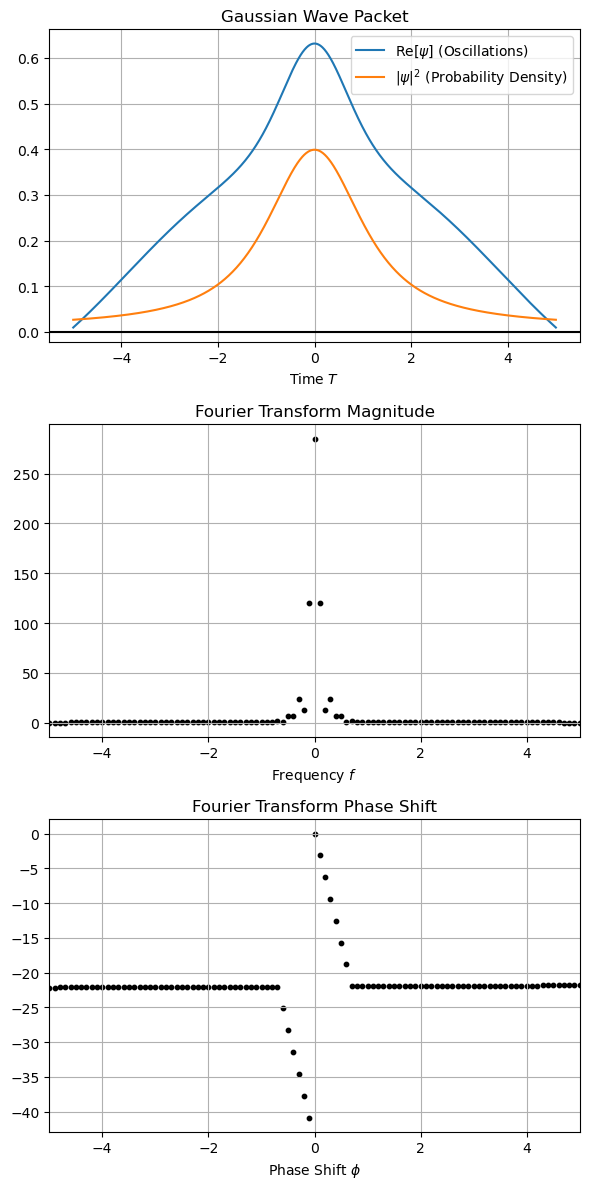

In [2]:
def gaussian_wave_packet(t, x, x0=0.0, sigma_x=1.0, k0=1.0, m=1.0, hbar=1.0):
    v_g = (hbar * k0) / m
    dispersion_factor = 1.0 + ((hbar * t) / (2.0 * m * sigma_x**2))**2
    norm = 1.0 / (2.0 * np.pi * sigma_x**2 * dispersion_factor)**0.25
    dx = x - x0 - v_g * t
    envelope_exponent = -(dx**2) / (4.0 * sigma_x**2 * dispersion_factor)
    dispersion_phase = (hbar * t * dx**2) / (4.0 * m * sigma_x**4 * dispersion_factor)
    propagation_phase = k0 * x - (hbar * k0**2 * t) / (2.0 * m)
    phase_offset = -0.25 * np.arctan((hbar * t) / (2.0 * m * sigma_x**2))
    
    psi = norm * np.exp(envelope_exponent) * np.cos(dispersion_phase + propagation_phase + phase_offset)
    prob_density = (norm**2) * np.exp(2.0 * envelope_exponent)
    
    return psi, prob_density

N = 1000
t_grid = np.linspace(-5, 5, N)
x_fixed = 0.0

psi, prob_density = gaussian_wave_packet(t_grid, x=x_fixed)

plt.figure(figsize=(6,12))

plt.subplot(3,1,1)
plt.plot(t_grid, psi, label=r"Re[$\psi$] (Oscillations)")
plt.plot(t_grid, prob_density, label=r"$|\psi|^2$ (Probability Density)")
plt.axhline(0, color='black')
plt.xlabel("Time $T$")
plt.title("Gaussian Wave Packet")
plt.grid(True)
plt.legend()

dt = t_grid[1] - t_grid[0]
f = 1
freqs = np.fft.fftfreq(N, dt)
Yk = np.fft.fft(psi)

Yk_mag = np.abs(Yk)
Yk_phase = np.angle(Yk)
Yk_phase = np.unwrap(Yk_phase)

plt.subplot(3,1,2)
plt.scatter(freqs, Yk_mag, color='k', s=10)
plt.xlim(-5.0, 5.0)
plt.xlabel("Frequency $f$")
plt.title("Fourier Transform Magnitude")
plt.grid(True)

plt.subplot(3,1,3)
plt.scatter(freqs, Yk_phase, color='k', s=10)
plt.xlim(-5.0, 5.0)
plt.xlabel(r"Phase Shift $\phi$")
plt.title("Fourier Transform Phase Shift")
plt.grid(True)

plt.tight_layout()
plt.show()


### Problem 2: Signal Processing in 1D (Fill in the blanks/Code to get to the desired result)

Steps performed: 

1) Create a composite signal from multiple sinusoids with three frequencies, get fft of clean signal
2) Add noise (gaussian noise)
3) Add a window (Hann)
4) Get fft of the noisy signal
5) filter frequencies below a threshold
6) get the inverse fft
7) compare the result

Discussion: Try running the procedure with a lower number of N (N<25000). What does lowering N do to the original signal? Will I still be able to recover that original signal if I add the noise below? Is there a limit of N to which I can recover the signal well? Why? (Answer in ~3 sentences)


[]

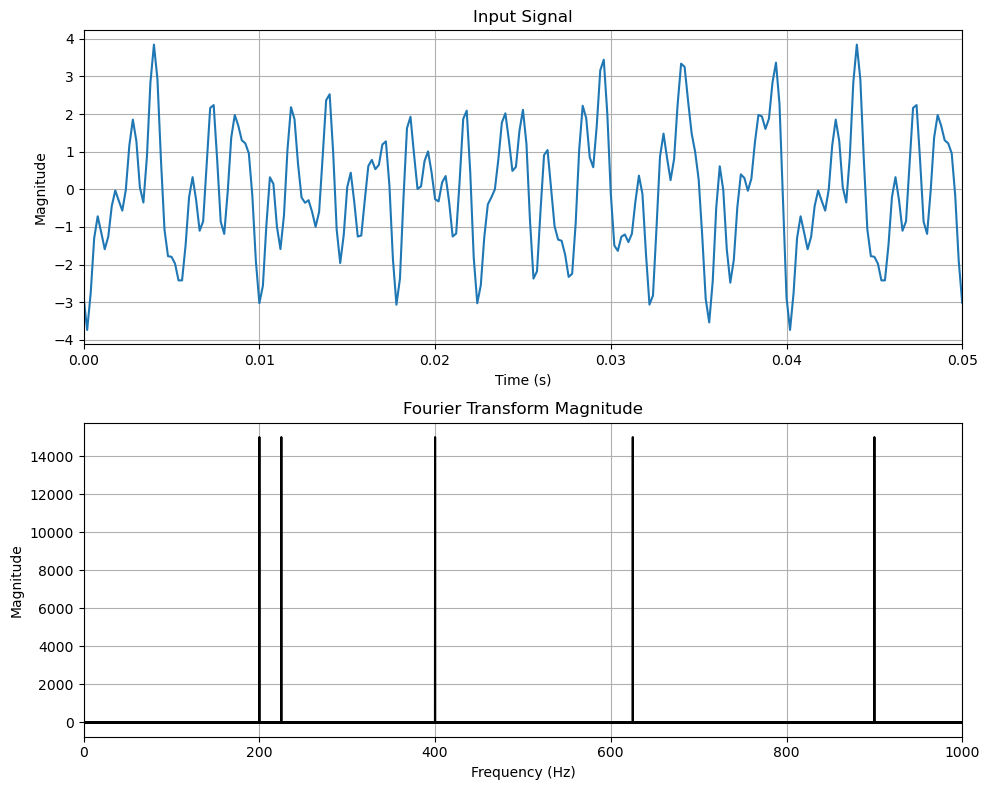

In [3]:
N = 30000
dt = 0.0002
t_ = np.arange(N)*dt
freqs = [200, 225, 400, 625, 900]
phase = [(i+1) * np.pi / (i+2) for i in range(5)]
signal_original = np.sum([np.cos(2*np.pi*f*t_ + p) for f, p in zip(freqs, phase)], axis=0)

freqs = np.fft.fftfreq(N, dt)
Yk = np.fft.fft(signal_original)
Yk_mag = np.abs(Yk)

plt.figure(figsize=(10,8))

plt.subplot(2,1,1)
plt.plot(t_, signal_original)
plt.xlim(0,0.05)
plt.xlabel("Time (s)")
plt.ylabel("Magnitude")
plt.title("Input Signal")
plt.grid(True)

plt.subplot(2,1,2)
plt.plot(freqs, Yk_mag, color='k')
plt.xlim(0,1000)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.title("Fourier Transform Magnitude")
plt.grid(True)

plt.tight_layout()
plt.plot()

[]

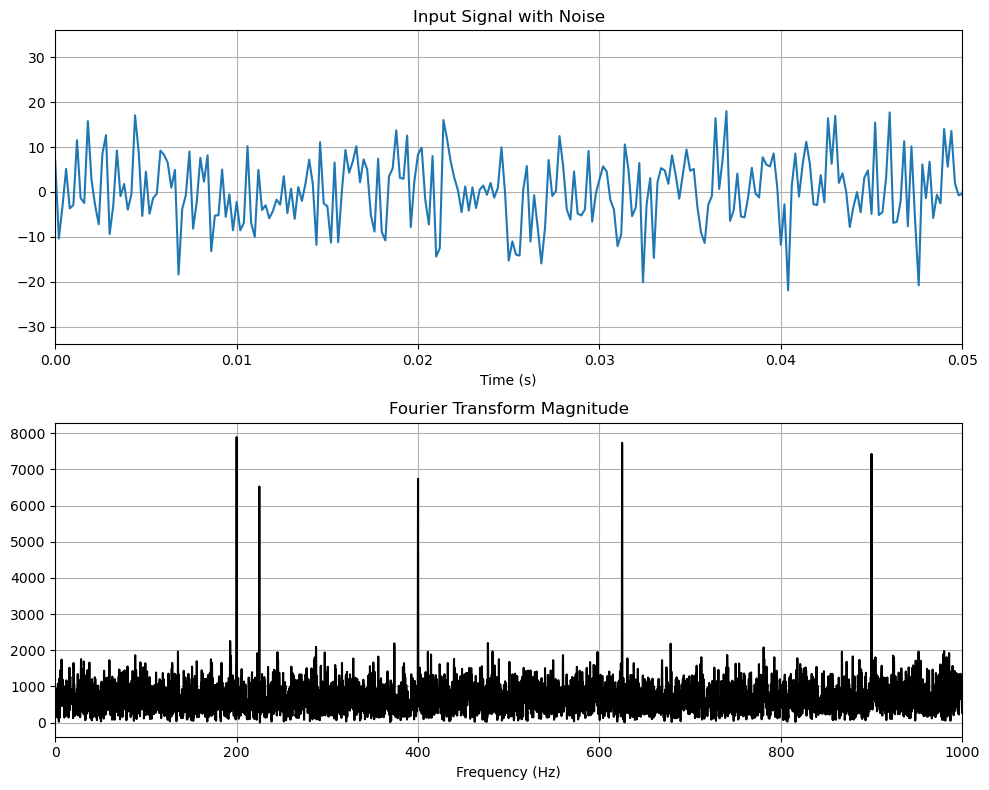

In [4]:
rng = np.random.default_rng()
mean = 0
std = 1.5
noise = rng.normal(loc = mean, scale = std, size = len(t_))
noisy_data = signal_original + noise*5

freqs = np.fft.fftfreq(N, dt)
window = np.hanning(len(noisy_data))
windowSigPeaks = np.abs(np.fft.fftshift(np.fft.fft(window)))
windowSigFreqs = np.fft.fftshift(np.fft.fftfreq(N, dt))
noisyFourier = np.fft.fft(noisy_data*window)
noisySigPeaks = np.abs(np.fft.fftshift(np.fft.fft(noisy_data*window)))

plt.figure(figsize=(10,8))

plt.subplot(2,1,1)
plt.plot(t_, noisy_data)
plt.xlim(0,0.05)
plt.xlabel("Time (s)")
plt.title("Input Signal with Noise")
plt.grid(True)

plt.subplot(2,1,2)
plt.plot(windowSigFreqs, noisySigPeaks, color='k', label='Noisy Signal (Hanning Window)')
plt.xlim(0,1000)
plt.xlabel("Frequency (Hz)")
plt.title("Fourier Transform Magnitude")
plt.grid(True)

plt.tight_layout()
plt.plot()

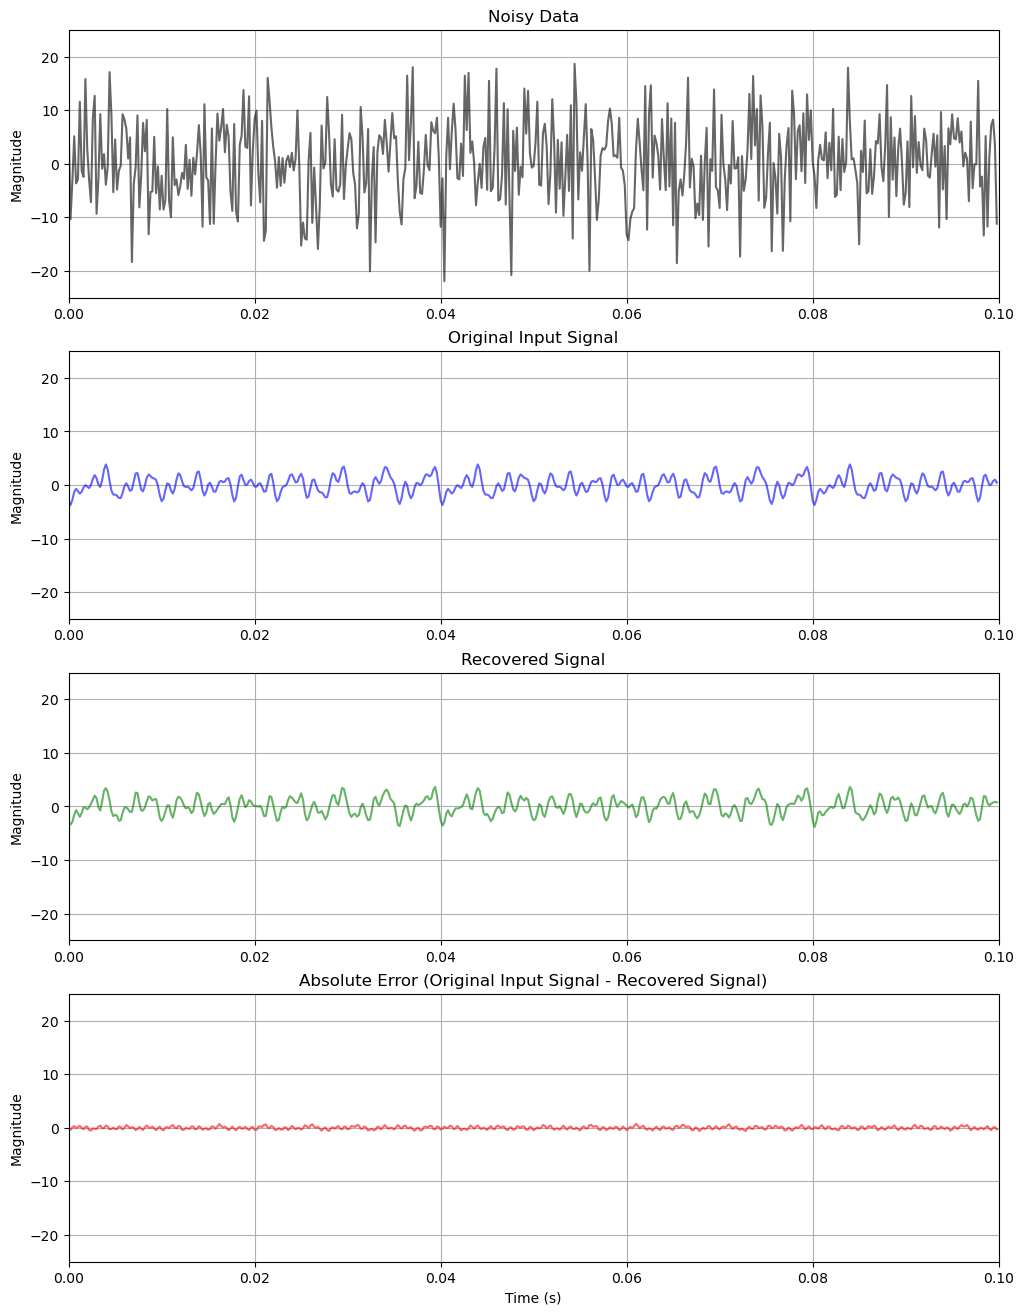

In [5]:
sigma_t = std * 5
s_freq = sigma_t * np.sqrt(N / 2)
threshold = s_freq * np.sqrt(2 * np.log(N))

Y_noisy = np.fft.fft(noisy_data)
Y_noisy_mag = np.abs(Y_noisy)

mask = Y_noisy_mag >= threshold
Y_filtered = Y_noisy * mask

recovered_signal = np.fft.ifft(Y_filtered).real
N_samples = 500

plt.figure(figsize=(12,16))

plt.subplot(4,1,1)
plt.plot(t_[:N_samples], noisy_data[:N_samples], color = 'black', alpha = 0.6)
plt.xlim(0,0.1)
plt.ylim(-25,25)
plt.ylabel("Magnitude")
plt.title("Noisy Data")
plt.grid(True)

plt.subplot(4,1,2)
plt.plot(t_[:N_samples], signal_original[:N_samples], color = 'blue', alpha = 0.6)
plt.xlim(0,0.1)
plt.ylabel("Magnitude")
plt.ylim(-25,25)
plt.ylabel("Magnitude")
plt.title("Original Input Signal")
plt.grid(True)

plt.subplot(4,1,3)
plt.plot(t_[:N_samples], recovered_signal[:N_samples], color = 'green', alpha = 0.6)
plt.xlim(0,0.1)
plt.ylim(-25,25)
plt.ylabel("Magnitude")
plt.title("Recovered Signal")
plt.grid(True)

plt.subplot(4,1,4)
plt.plot(t_[:N_samples], signal_original[:N_samples] - recovered_signal[:N_samples], color = 'red', alpha = 0.6)
plt.xlim(0,0.1)
plt.ylim(-25,25)
plt.xlabel("Time (s)")
plt.ylabel("Magnitude")
plt.title("Absolute Error (Original Input Signal - Recovered Signal)")
plt.grid(True)

plt.show()


### Problem 3: Aliasing
1) Using different sampling frequencies (uniform sampling), generate a sinusoidal signal. Note the sampling frequencies, and the signal frequency. Use a sampling frequency above the Nyquist frequency, and another one below it.
3) Get their fourier transforms. Are they the same?
4) Plot: Show the fourier transform of an aliased signal, how it looks like in the time-domain, and how the actual signal looks like in the time domain if it's not aliased.
   
Discussion: Explain the report figure. Note the frequency of the signal you wanted to sample, the sampling frequencies used for the aliased and the non-aliased wave

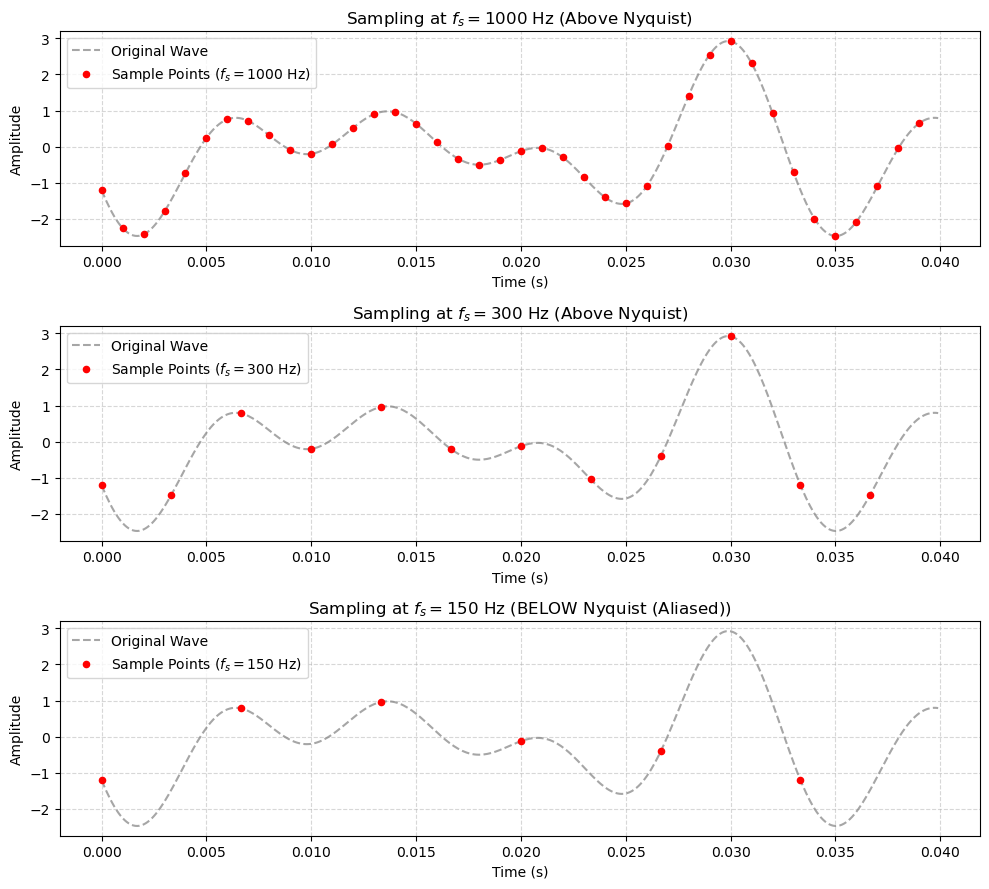

In [7]:
freqs = [60, 90, 120]
phases = [(i + 1) * np.pi / (i + 2) for i in range(len(freqs))]
f_max = max(freqs)
f_nyquist = 2 * f_max
duration = 0.04

def generate_sampled_signal(fs, duration):
    dt = 1.0 / fs
    t = np.arange(0, duration, dt)
    signal = np.sum([np.cos(2 * np.pi * f * t + p) for f, p in zip(freqs, phases)], axis=0)
    return t, signal

t_ref, signal_ref = generate_sampled_signal(fs=10000, duration=duration)

sampling_rates = [1000, 300, 150]

plt.figure(figsize=(10, 9))

for idx, fs in enumerate(sampling_rates, 1):
    t_s, sig_s = generate_sampled_signal(fs, duration)
    
    plt.subplot(len(sampling_rates), 1, idx)
    plt.plot(t_ref, signal_ref, color='gray', linestyle='--', alpha=0.7, label='Original Wave')
    plt.scatter(t_s, sig_s, color='red', s=20, zorder=3, label=f'Sample Points ($f_s = {fs}$ Hz)')
    
    status = "Above Nyquist" if fs > f_nyquist else "BELOW Nyquist (Aliased)"
    plt.title(f"Sampling at $f_s = {fs}$ Hz ({status})")
    plt.xlabel("Time (s)")
    plt.ylabel("Amplitude")
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.legend(loc='upper left')

plt.tight_layout()
plt.show()

#### Problem code summary

The script models a quantum wave packet dispersion and different multi-frequency signals. We primarily use np.fft.fft (and other forms of FTs), along with defining functions to setup the fourier transforms. Then, we use statistical frequency-domain thresholding to clean noisy data, recover the original data, and demonstrate the Nyquist theorem to highlight signal aliasing.

---
## Section 3: Notes

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

### Fourier transform (from $t$-space to $\omega$-space)
$$ Y(\omega) = \int_{-\infty}^{+\infty} dt \frac{e^{-i\omega t}}{\sqrt{2\pi}}y(t)$$

### Inverse Fourier transform (from $\omega$-space to $t$-space)
$$ y(t) = \int_{-\infty}^{+\infty} d\omega Y(\omega) \frac{e^{i\omega t}}{\sqrt{2\pi}}$$

Something to think about: while we essentially do numerical integration, we do not impose h. Instead, we utilize the spacing of the dataset.

### Discrete FT/IFT

$$ Y_n = \frac{1}{\sqrt{2\pi}} \sum_{k=1}^N \left[(\cos(nk\theta)\Re\{y_k\}  +\sin(nk\theta)\Im\{y_k\} +i(\cos(nk\theta)\Im\{y_k\} −\sin(nk\theta)\Re\{y_k\})]\right]$$

$$ y_k = \frac{\sqrt{2\pi}}{N} \sum_{k=1}^N \left[(\cos(nk\theta)\Re\{Y_n\}  -\sin(nk\theta)\Im\{Y_n\} +i(\cos(nk\theta)\Im\{Y_n\} +\sin(nk\theta)\Re\{Y_n\})]\right]$$

Why bother it doing this way? 

It cleanly splits the real and imaginary part for both inputs and outputs, so that you can use a pair of floats rather than an aggregate complex data type (complex128 is just a pair of float64 anyway).

Using $Z=e^{−i\theta}, \rightarrow Z^{\pm nk} = e^{\mp ink\theta} = \cos(nk\theta)\mp i\sin(nk\theta)$.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

N = 1000
x = np.linspace(0, 18*2*np.pi, N)
deltaT = x[1] - x[0]

f = 1
y = np.cos(2*np.pi*f*x)

freqs = np.fft.fftfreq(N, deltaT)
Yk = np.fft.fft(y)

# # Q: Why do fftshift?
# Yk = np.fft.fftshift(Yk)

Yk_mag = np.abs(Yk)
Yk_phase = np.angle(Yk)
# Q: Why unwrap?
Yk_phase = np.unwrap(Yk_phase)

fig, ax = plt.subplots(1,2)

ax[0].plot(freqs, Yk_mag, "k.")
ax[1].plot(freqs, Yk_phase, "k.")
ax[0].set_xlim(0, 4)

### Waveforms of interest
- Sinusoid (single frequency, varying phase shift)
- Sum of sinusoids with different frequencies and phases
- Product of sinusoids with different frequencies and phases
- Square wave (both single and periodic)
- Triangle wave (sawtooth, ramp, reverse ramp)
- Gaussian function
- Finite-time sinusoid
- Gaussian wave packet

In [ ]:
t = np.linspace(0,10,1000) #Create 100 pts from 0 to 10
x = np.sin(2*np.pi*2*t)

In [ ]:
plt.plot(t,x)
plt.xlabel("t")
plt.ylabel("x")

In [ ]:
x_ft = np.fft.fft(x)
np.fft.fftfreq?

### Plotting

In [ ]:
fig, ax = plt.subplots(3, 1, figsize=(3, 5))

ax[0].set_title("Put input signal here")
ax[0].set_xlabel("Time t")
#....
ax[1].set_title("Put FT magnitude here")
ax[1].set_xlabel("Frequency f")
#....
ax[2].set_title("Put FT phase here")
ax[2].set_xlabel("Frequency f")
#...

fig.tight_layout()

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3))

ax[0].set_title("Put input signal here")
ax[0].set_xlabel("Time t")
#....
ax[1].set_title("Put FT magnitude here")
ax[1].set_xlabel("Frequency f")
#....
ax[2].set_title("Put FT phase here")
ax[2].set_xlabel("Frequency f")
#...

fig.tight_layout()

In [ ]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3))
ax_t, ax_f, ax_p = axs

t = np.linspace(0, 10, 2048)
f = 0.5 # Frequency
T = 1/(f) # Period
f2 = 0.8 # Frequency
T2 = 1/(f2) # Period


ax_t.set_title("Put input signal here")
ax_t.set_xlabel("Time t")
ax_t.plot(t, (t%T)/T, label="f = 0.5")
ax_t.plot(t, (t%T2)/T2, label="f = 0.8")
ax_t.legend()
#....
ax_f.set_title("Put FT magnitude here")
ax_f.set_xlabel("Frequency f")
#....
ax_p.set_title("Put FT phase here")
ax_p.set_xlabel("Frequency f")
#...


for ax in axs:
    ax.grid(True)
fig.tight_layout()

## 1-D convolution

In [ ]:
a = [1,1,1,0,0,0,0,1,1,1,0,0,0,1,0,0,0,1,1,1,0,1,1,0,0,0,0]
v = [1,1,1]



In [ ]:
plt.plot(np.arange(len(np.convolve(a,v, mode='full'))), np.convolve(a,v, mode='full'))

### Convolution attempt (bringing circuits analogy) 

In [ ]:
import numpy as np
from scipy import signal
import matplotlib.pyplot as plt
N = 500
t = np.linspace(0, 1, N, endpoint=False)
t_input = np.linspace(0, 5, N*5, endpoint=False)
signal_freq = 5
# dt = t[1] - t[0]
# nonsinu_signal = signal.square(2 * np.pi * signal_freq * t)

In [ ]:
tau = 0.1
h_t = np.exp(-t/tau)
input_signal = signal.square(2 * np.pi * signal_freq * t_input) #cont_signal(t, freq)

In [ ]:
fig, ax = plt.subplots(figsize = (15,5))
ax.plot(t, h_t, label = "impulse response")
ax.plot(t_input, input_signal, label= "driving signal")
ax.legend()

In [ ]:
response = np.convolve(input_signal, h_t, mode = "same")

In [ ]:
fig, ax = plt.subplots(figsize = (15,5))
#ax.plot(t, input_signal)
ax.plot(t_input, response)

In [ ]:
fourier_length = len(h_t) + len(input_signal) - 1

In [ ]:
fourier_input = np.fft.fft(input_signal, n = fourier_length)
fourier_h = np.fft.fft(h_t, n = fourier_length)

In [ ]:
fourier_response = fourier_h*fourier_input 

In [ ]:
response = np.real(np.fft.ifft(fourier_response))

In [ ]:
fig, ax = plt.subplots(figsize = (15,5))

ax.plot(response)